<a href="https://colab.research.google.com/github/Sinchana-06clg/4IK25CS197_DAV_LAB/blob/main/4IK25CS197_Experiential_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student depression detection**

1: Imports and load

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/Student_Depression_Dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (4464, 13)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


2: Understand the data

In [ ]:
print(df.columns.tolist())
df.info()
df.describe(include='all').T

['Gender', 'Age', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'Current_semester', 'CGPA', 'friend_circle', 'Health_condition', 'Cost_without_study', 'Home_division', 'Depression']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        446

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,4464,2,Female,2462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,4464.0,NaN,NaN,NaN,22.619176,2.02298,17.0,21.0,23.0,24.0,28.0
Family_background,4464,3,Middle class,2642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Relationship_status,4464,3,Single,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_status,4464,3,Unmarried,3619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Living_style,4464,2,Bachelor,2449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_semester,4464.0,NaN,NaN,NaN,5.40121,2.578476,0.0,3.0,5.0,7.0,13.0
CGPA,4464.0,NaN,NaN,NaN,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0
friend_circle,4464,2,Yes,3215,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Health_condition,4464,4,Normal,1787,NaN,NaN,NaN,NaN,NaN,NaN,NaN


3: Data cleaning

In [ ]:
df.columns = df.columns.str.strip()
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

print("Missing after cleaning:", df.isnull().sum().sum())
print("Shape after cleaning:", df.shape)

Missing values:
 Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64
Duplicates: 0
Missing after cleaning: 0
Shape after cleaning: (4464, 13)


4:  Preprocessing--Detect target and column types

In [ ]:
target = next((c for c in df.columns if 'depress' in c.lower()), df.columns[-1])
print("Target column:", target)

num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target]
cat_cols = [c for c in df.select_dtypes(include='object').columns if c != target]
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

df[target].value_counts()

Target column: Depression
Numeric: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Categorical: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division']


,count
Depression,
No,3263
Yes,1201


5: Univariate analysis

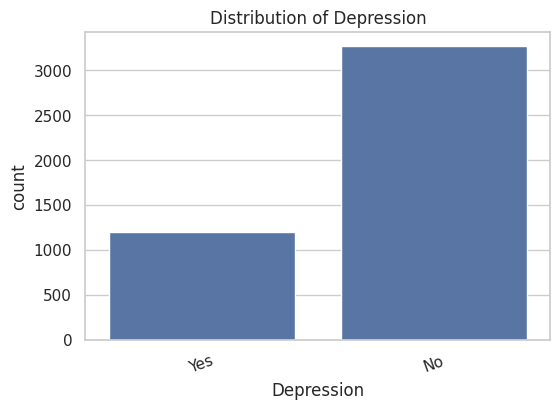

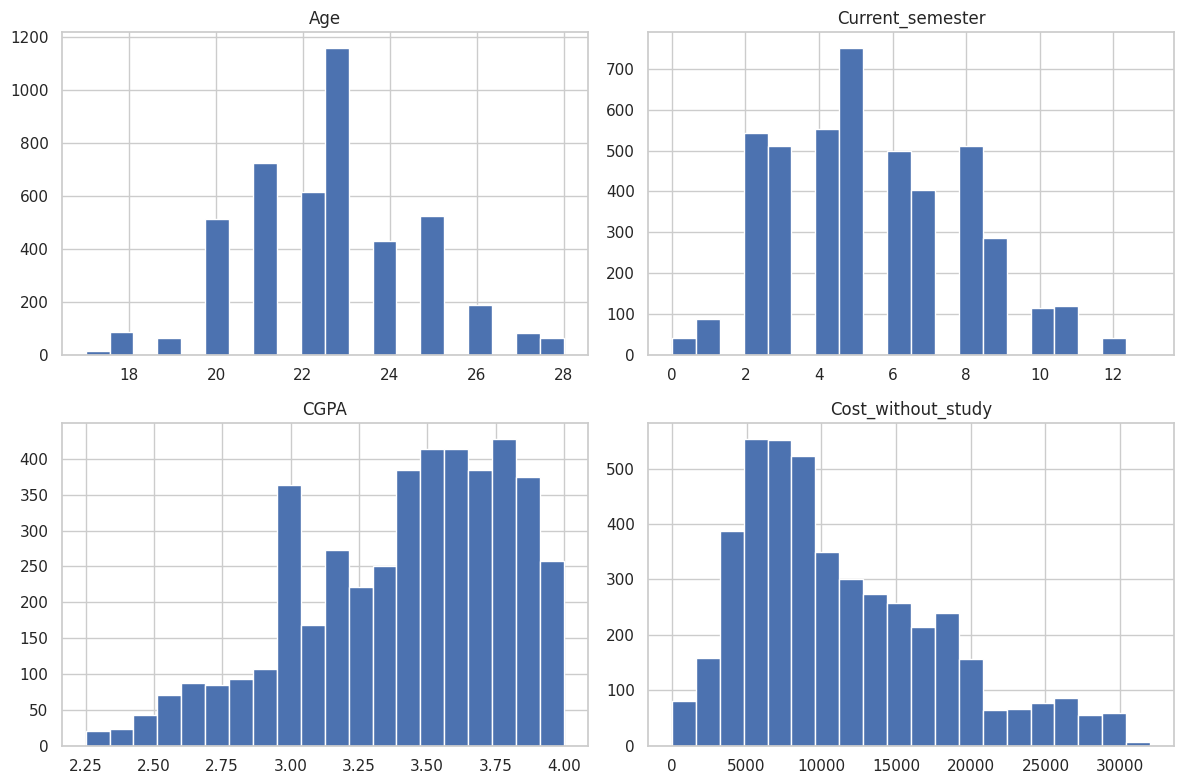

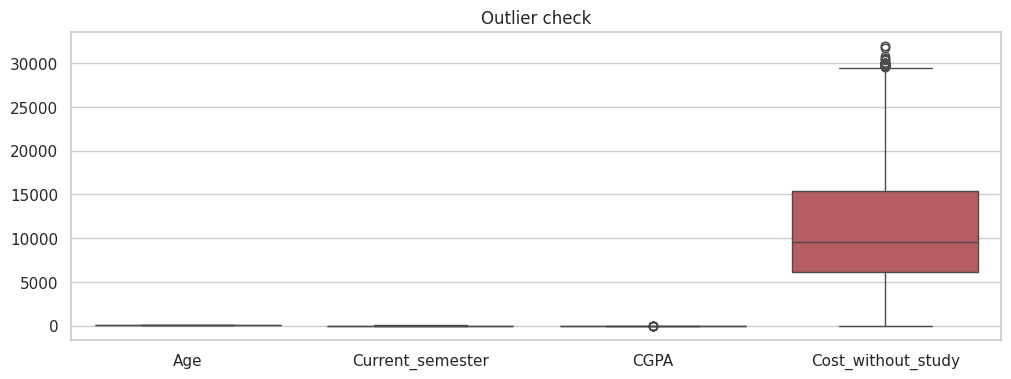

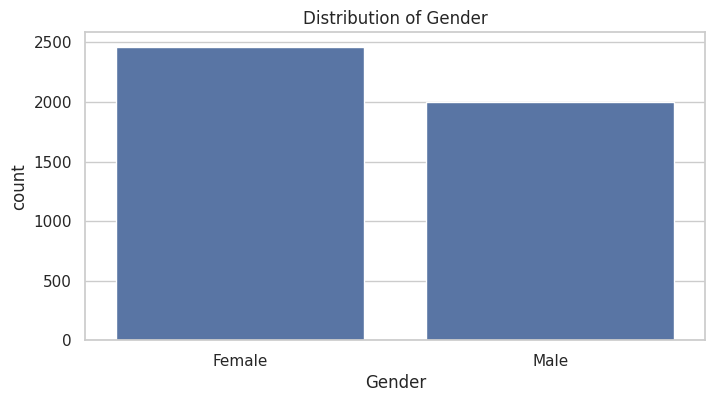

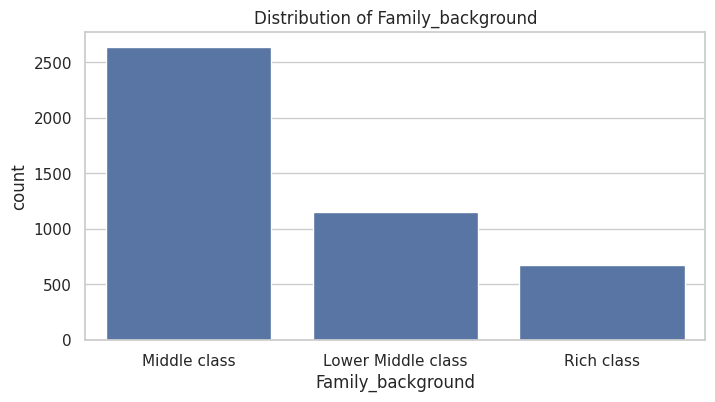

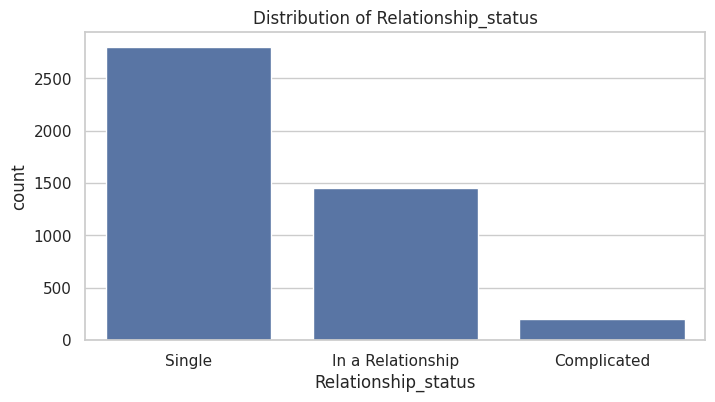

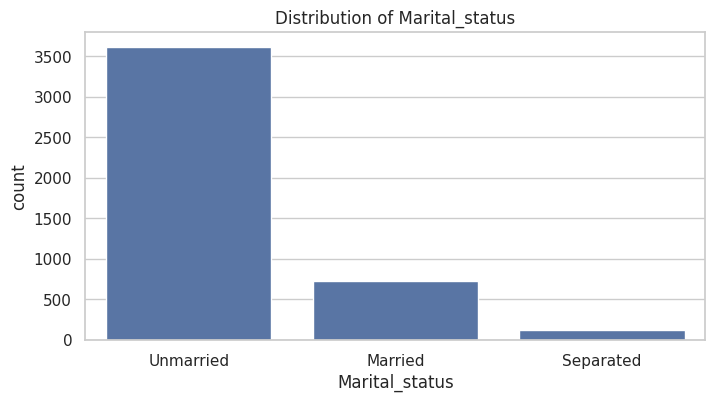

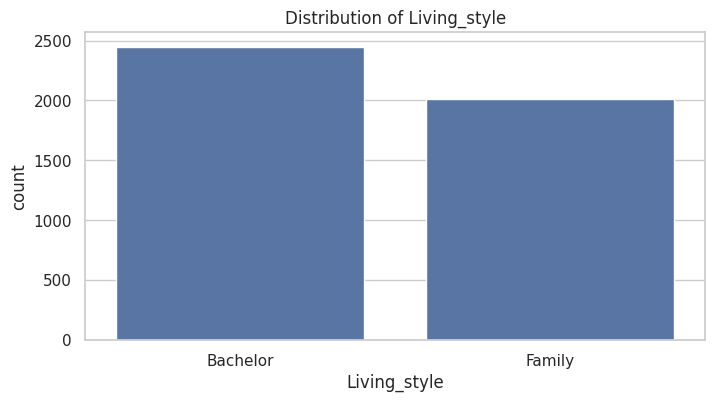

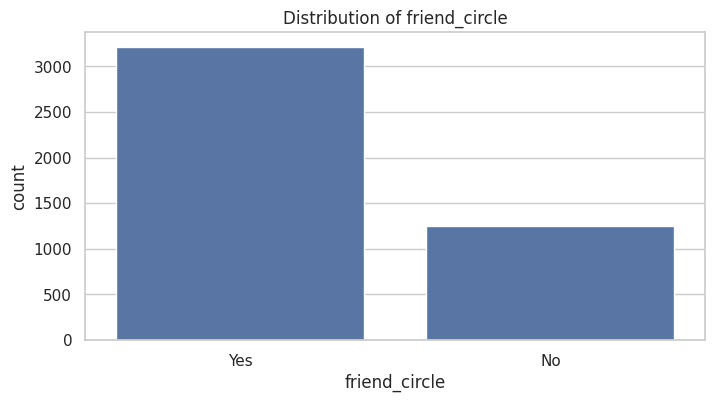

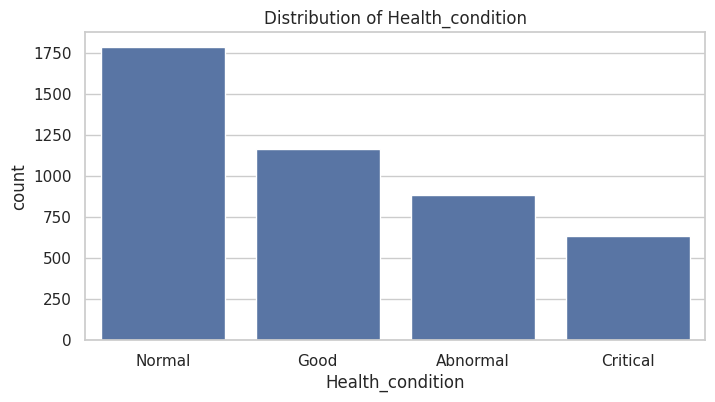

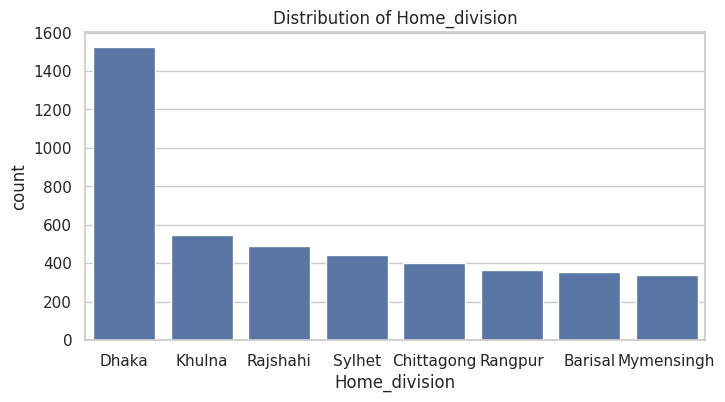

In [ ]:
# Target distribution
plt.figure(figsize=(6,4))
sns.countplot(x=target, data=df)
plt.title(f"Distribution of {target}")
plt.xticks(rotation=20)
plt.show()

# Numeric columns
df[num_cols].hist(figsize=(12,8), bins=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,4))
sns.boxplot(data=df[num_cols])
plt.xticks(rotation=0)
plt.title("Outlier check")
plt.show()

# Categorical columns
for col in cat_cols:
    if df[col].nunique() <= 15:
        plt.figure(figsize=(8,4))
        sns.countplot(x=col, data=df, order=df[col].value_counts().index)
        plt.title(f"Distribution of {col}")
        plt.xticks(rotation=0)
        plt.show()

6: Bivariate analysis (each factor vs target)

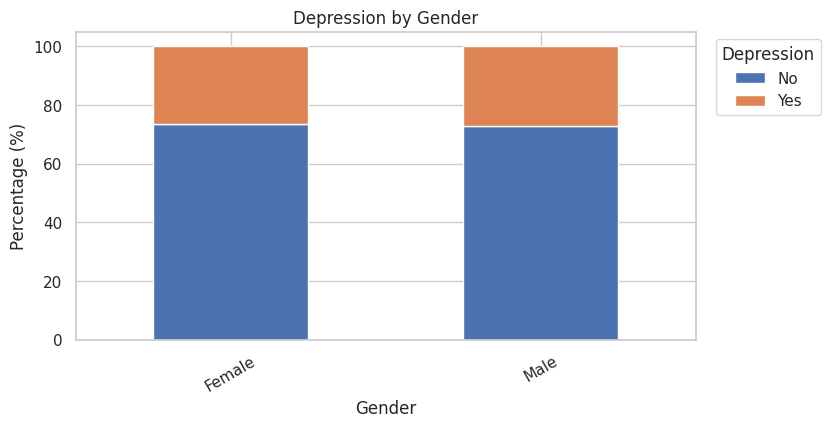

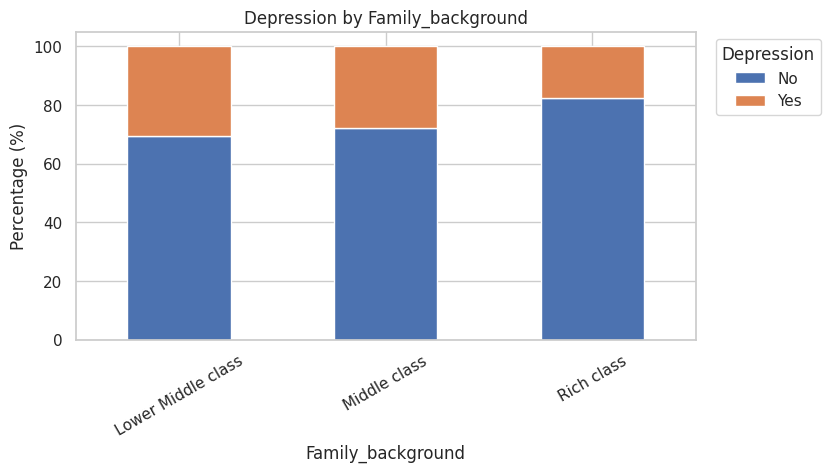

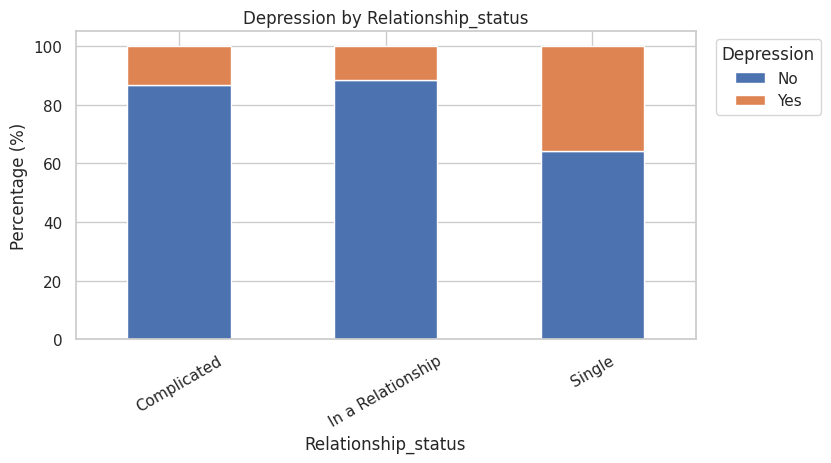

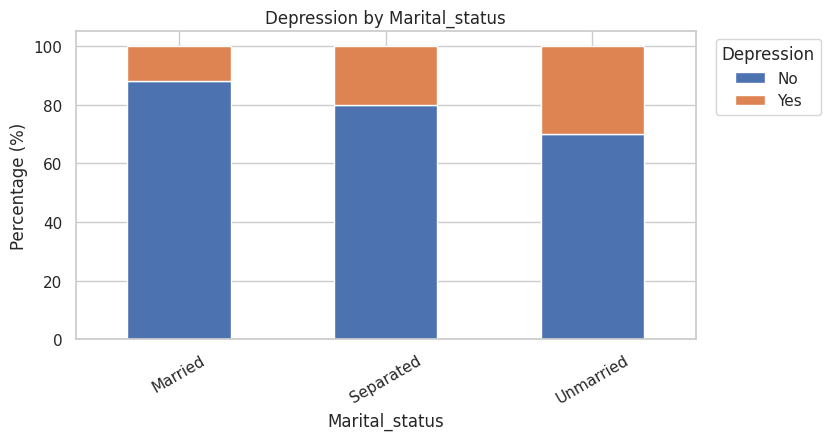

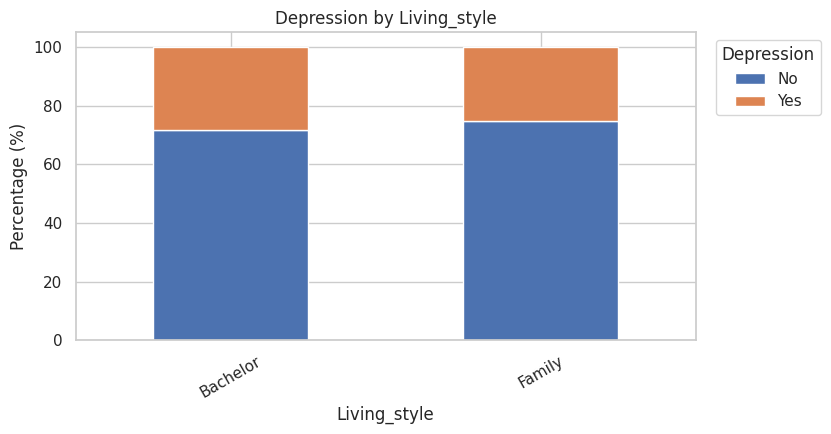

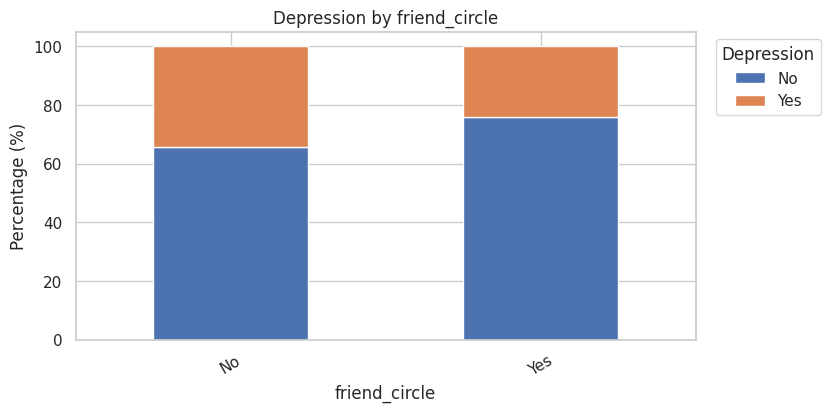

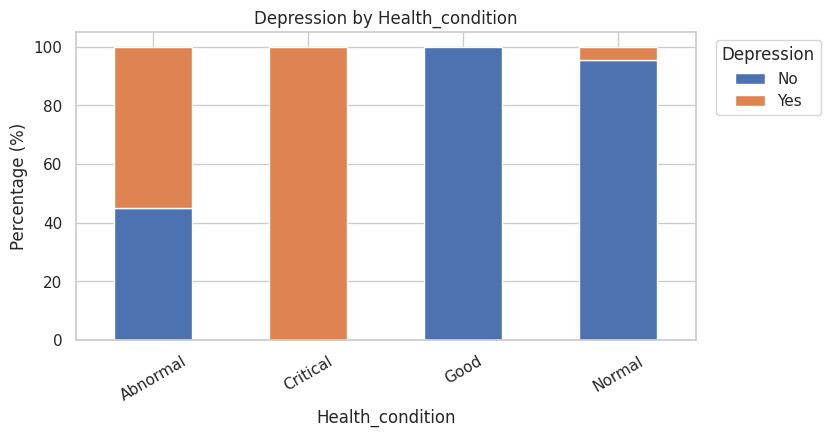

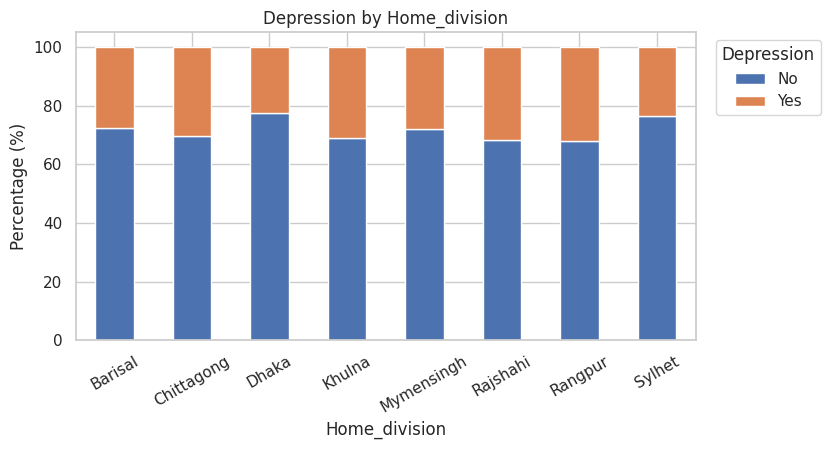

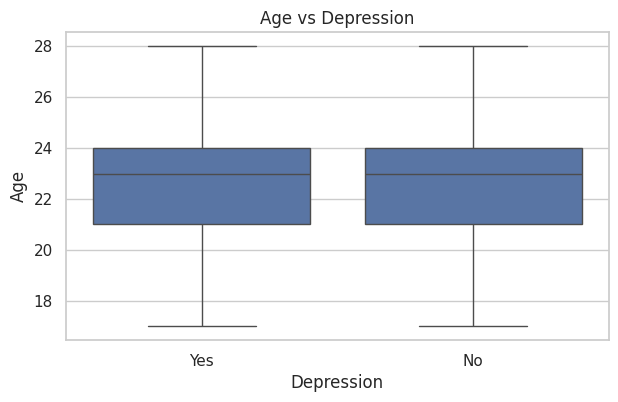

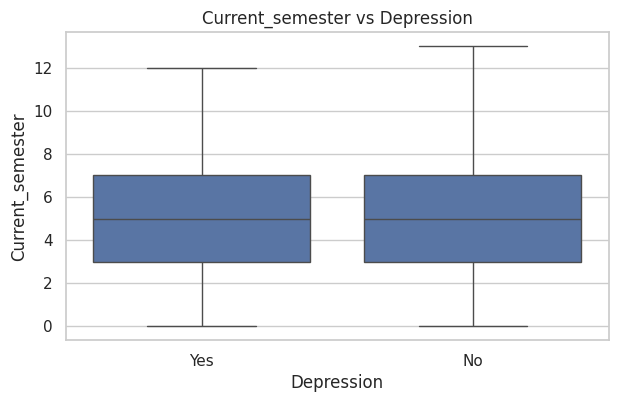

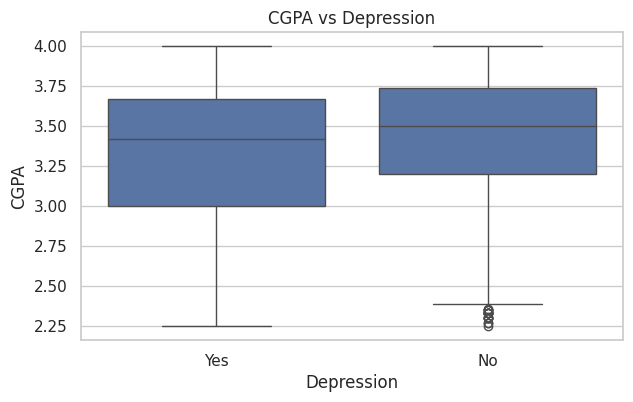

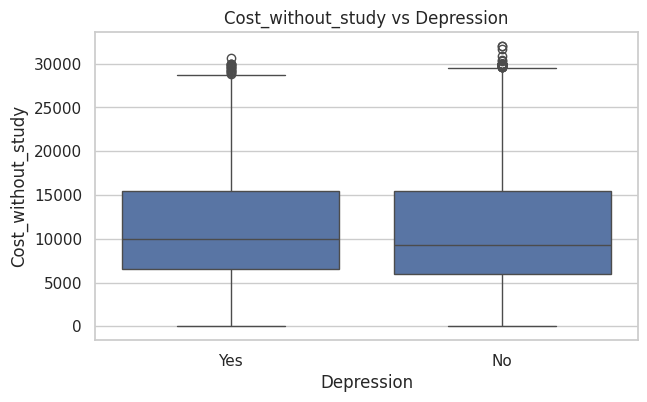

In [ ]:
# Categorical factors vs target (percentage stacked bars)
for col in cat_cols:
    if df[col].nunique() <= 12 and df[target].nunique() <= 10:
        ct = pd.crosstab(df[col], df[target], normalize='index') * 100
        ct.plot(kind='bar', stacked=True, figsize=(8,4))
        plt.ylabel("Percentage (%)")
        plt.title(f"{target} by {col}")
        plt.xticks(rotation=30)
        plt.legend(title=target, bbox_to_anchor=(1.02, 1), loc='upper left')
        plt.show()

# Numeric factors vs target
for col in num_cols:
    if df[target].nunique() <= 10:
        plt.figure(figsize=(7,4))
        sns.boxplot(x=target, y=col, data=df)
        plt.title(f"{col} vs {target}")
        plt.show()

7: Correlation heatmap

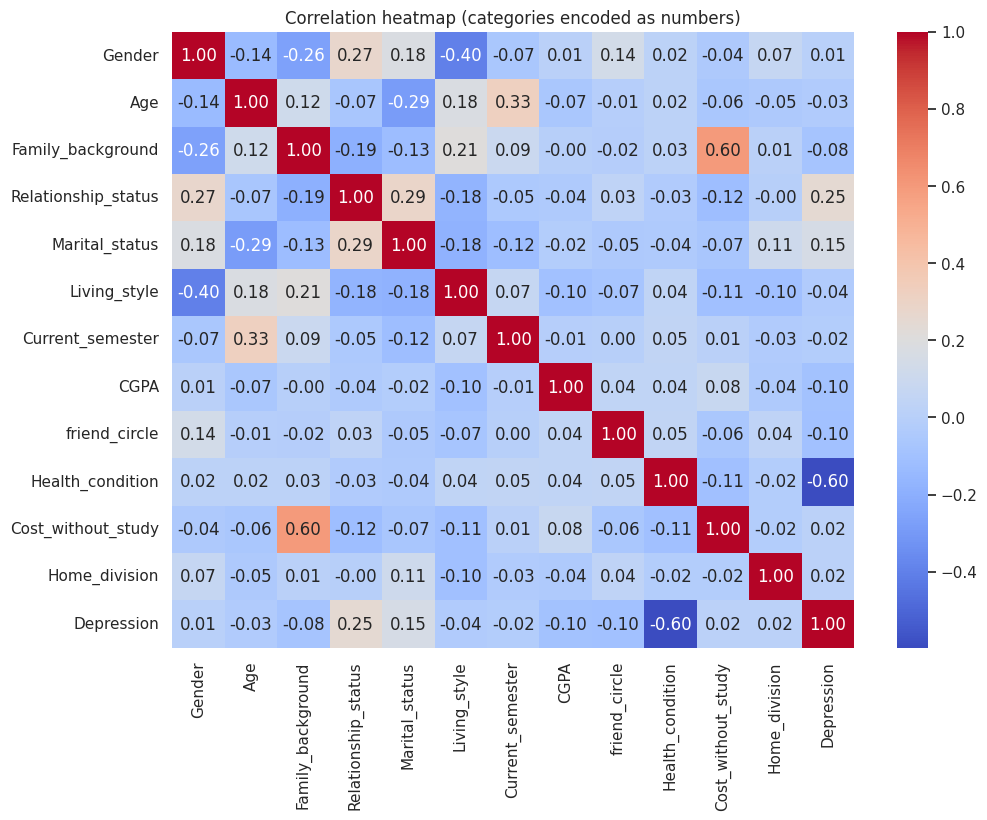

Relationship_status    0.25
Marital_status         0.15
Home_division          0.02
Cost_without_study     0.02
Gender                 0.01
Current_semester      -0.02
Age                   -0.03
Living_style          -0.04
Family_background     -0.08
CGPA                  -0.10
friend_circle         -0.10
Health_condition      -0.60
Name: Depression, dtype: float64


In [ ]:
corr_df = df.copy()
for col in corr_df.select_dtypes(include='object').columns:
    corr_df[col] = corr_df[col].astype('category').cat.codes

plt.figure(figsize=(11,8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap (categories encoded as numbers)")
plt.show()

print(corr_df.corr()[target].drop(target).sort_values(ascending=False).round(2))

8: Multivariate analysis

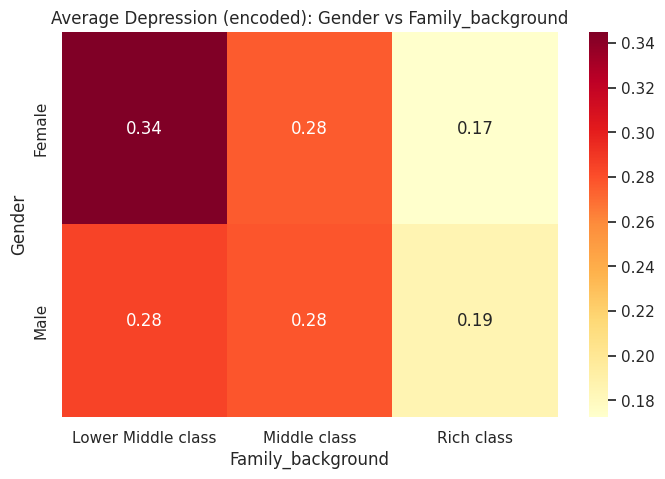

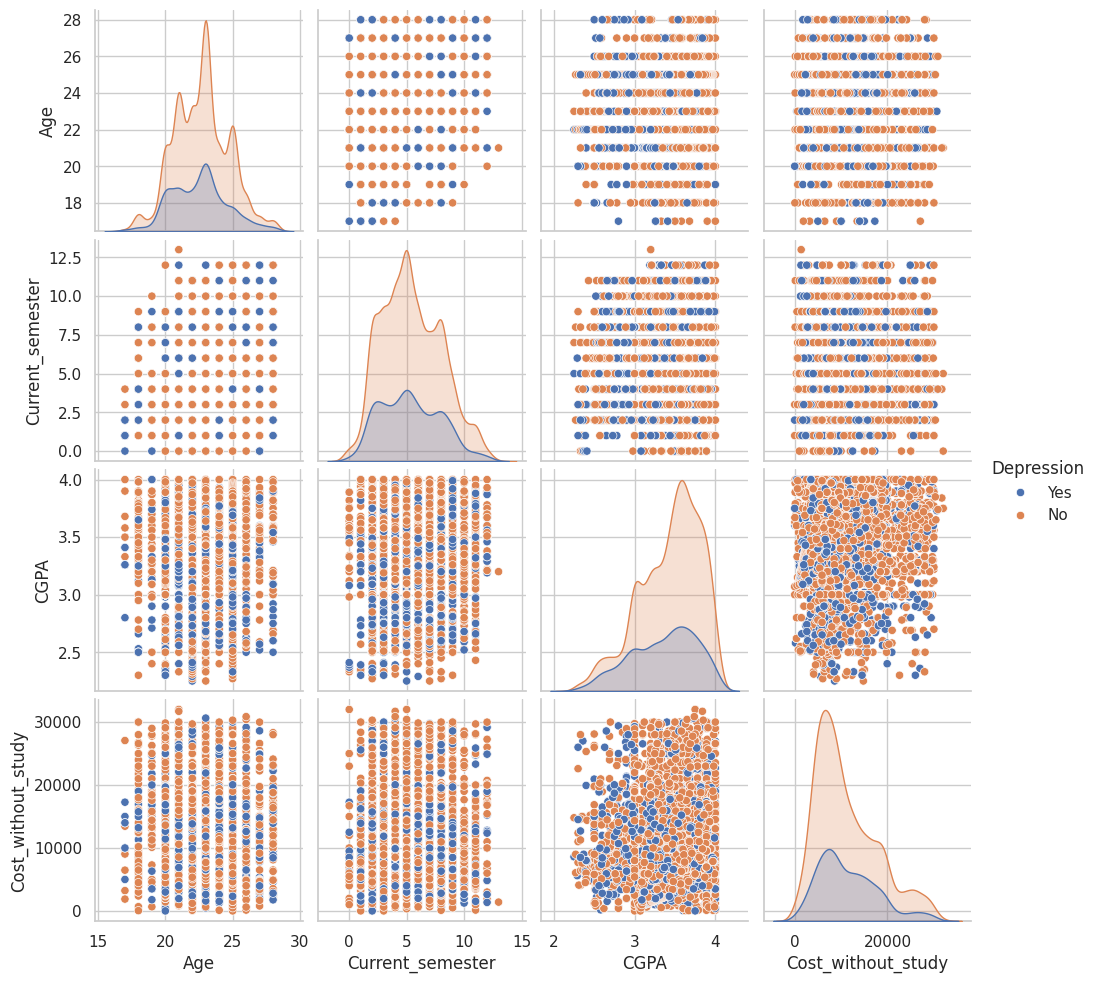

In [ ]:
if len(cat_cols) >= 2 and df[target].nunique() <= 10:
    a, b = cat_cols[0], cat_cols[1]
    pivot = pd.crosstab(df[a], df[b], values=corr_df[target], aggfunc='mean')
    plt.figure(figsize=(8,5))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlOrRd")
    plt.title(f"Average {target} (encoded): {a} vs {b}")
    plt.show()

if len(num_cols) >= 2:
    sns.pairplot(df[num_cols[:4] + [target]], hue=target if df[target].nunique() <= 10 else None)
    plt.show()

9: Numbers for your insights

In [ ]:
print("Target distribution (%):")
print((df[target].value_counts(normalize=True) * 100).round(1))

for col in cat_cols:
    if df[col].nunique() <= 8 and df[target].nunique() <= 10:
        print(f"\n{target} by {col} (%):")
        print((pd.crosstab(df[col], df[target], normalize='index') * 100).round(1))

Target distribution (%):
Depression
No     73.1
Yes    26.9
Name: proportion, dtype: float64

Depression by Gender (%):
Depression    No   Yes
Gender                
Female      73.4  26.6
Male        72.7  27.3

Depression by Family_background (%):
Depression            No   Yes
Family_background             
Lower Middle class  69.4  30.6
Middle class        72.3  27.7
Rich class          82.4  17.6

Depression by Relationship_status (%):
Depression             No   Yes
Relationship_status            
Complicated          86.8  13.2
In a Relationship    88.5  11.5
Single               64.1  35.9

Depression by Marital_status (%):
Depression        No   Yes
Marital_status            
Married         88.0  12.0
Separated       80.0  20.0
Unmarried       69.9  30.1

Depression by Living_style (%):
Depression      No   Yes
Living_style            
Bachelor      71.7  28.3
Family        74.8  25.2

Depression by friend_circle (%):
Depression       No   Yes
friend_circle            
No    